# Which Retrieval Strategy Should You Use? Keyword, Vector, Hybrid and Graph Search in Oracle AI Database

Every retrieval-augmented application, and every agent that reads from its memory, starts with one question: **which documents does the model get to see?** This notebook answers it by measurement. Four retrieval strategies, plus a reranker, run as SQL on one Oracle AI Database over two public BEIR datasets whose right answers are known:

| Strategy | What finds the documents | Oracle feature |
|---|---|---|
| **Keyword** | shared words, weighted by how rare they are | Oracle Text `CONTAINS` and `SCORE` |
| **Vector** | closeness of meaning in an embedding space | Oracle AI Vector Search, `VECTOR_DISTANCE` |
| **Hybrid** | both lists, fused into one | weighted score fusion, in one SQL statement |
| **Graph** | vector hits, then their neighbours in a graph of similar documents | a SQL property graph, `GRAPH_TABLE … MATCH` |
| **+ Reranker** | a second model reorders the hybrid top 10 | a local cross-encoder |

The two datasets are **FiQA-2018**, personal-finance questions answered from StackExchange and Reddit posts, and **SciFact**, scientific claims matched to the abstracts that support or refute them. Everything runs on this machine: local models through FastEmbed and Oracle AI Database in a container. No API key is needed.

## The plan

| Part | Question | Output |
|---|---|---|
| 0 | Setup | Oracle, two local models, optional tracing |
| 1 | What data, and how is retrieval graded? | two datasets in Oracle; four metrics on one worked example |
| 2 | How does each strategy work? | the SQL of each; one question through all five, side by side |
| 3 | Which wins, on which data? | one results table per dataset, one chart, one sweep of the hybrid weight |
| 4 | Which strategy should you use? | a decision table and a diagram |

A run takes about 6 minutes when the tables from an earlier run are in Oracle; the first run on an empty database also embeds 25,183 documents, which takes longer. Parts 1 to 4 end with **📌 Key Takeaways**.

### ⭐ Live path

| Section | What to show | Minutes |
|---|---|---|
| 2.6 ⭐ | One question through all five strategies, relevant documents marked | 4 |
| 3.1 ⭐ | The results tables | 4 |
| 3.3 ⭐ | Why equal weighting loses: the hybrid weight sweep | 3 |
| 4.1 ⭐ | The decision table | 3 |

### Reference architecture

<img src="img/retrieval_strategies.png" alt="Reference architecture: two BEIR datasets, local models, four strategies as SQL in Oracle, a reranker, the metrics and the choice" width="898">

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    D["BEIR ON HUGGING FACE<br/>FiQA-2018 · SciFact · pinned revisions"]:::user
    M["LOCAL MODELS · FastEmbed<br/>bge-small-en-v1.5 · ms-marco cross-encoder"]:::llm
    D --> M
    subgraph ORA["ORACLE AI DATABASE · every strategy is one SQL statement"]
        K["KEYWORD<br/>Oracle Text"]:::db
        V["VECTOR<br/>VECTOR_DISTANCE"]:::db
        H["HYBRID<br/>weighted fusion"]:::db
        G["GRAPH<br/>GRAPH_TABLE"]:::db
    end
    M --> K & V & H & G
    H --> R["RERANKER<br/>hybrid top 10"]:::dm
    K & V & G & R --> E["METRICS<br/>nDCG@10 · Recall@10 · Precision@10 · MRR@10 · latency"]:::code
    E --> C["WHICH STRATEGY TO USE"]:::gate
    style ORA fill:#020d06,stroke:#059669,color:#6ee7b7
```

</details>

# Part 0 · Setup

## 0.1 · Install the dependencies

**Why this step.** Every model runs locally through FastEmbed, the data is read from Hugging Face with pandas, and every query goes to Oracle through `oracledb`.

**How:** install only what the kernel is missing.

In [1]:
import importlib.util
import subprocess
import sys

requirements = {
    "oracledb": "oracledb>=3.4", "fastembed": "fastembed>=0.8", "pandas": "pandas>=2.0", "pyarrow": "pyarrow>=15",
    "numpy": "numpy>=1.26", "huggingface_hub": "huggingface_hub>=0.30", "fsspec": "fsspec>=2024.2",
    "matplotlib": "matplotlib>=3.8", "dotenv": "python-dotenv>=1.0",
    "arize.otel": "arize-otel>=0.14", "opentelemetry.sdk": "opentelemetry-sdk>=1.45",   # optional tracing (0.4)
}
missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Notebook dependencies ready ✓", f"(installed {missing})" if missing else "")

Notebook dependencies ready ✓ 


## 0.2 · Connect to Oracle AI Database

**Why this step.** Every strategy runs as SQL in Oracle AI Database.

**How:** start the database from the `part7` folder with `./oracle.sh start` (Oracle AI Database Free on `localhost:1521`, with Oracle Text, vector search and SQL property graphs), connect, and define `sql()`: a query returns its rows as dicts, a write commits and returns its row count. Every table here starts with `BEIR7_`.

In [2]:
import os
import time

import numpy as np
import oracledb
import pandas as pd

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
oracledb.defaults.fetch_lobs = False
conn = oracledb.connect(user=os.environ.get("ORACLE_USER", "VECTOR"),
                        password=os.environ.get("ORACLE_PASSWORD", "VectorPwd_2025"),
                        dsn=os.environ.get("ORACLE_DSN", "localhost:1521/FREEPDB1"))


def sql(statement: str, **binds):
    """Run one statement: queries return a list of dicts, writes commit and return the row count."""
    with conn.cursor() as cur:
        cur.execute(statement, binds)
        if cur.description is None:
            conn.commit()
            return cur.rowcount
        names = [d[0].lower() for d in cur.description]
        return [dict(zip(names, row)) for row in cur.fetchall()]


print(sql("SELECT banner_full FROM v$version")[0]["banner_full"].splitlines()[0])

Oracle AI Database 26ai Free Release 23.26.2.0.0 - Develop, Learn, and Run for Free


## 0.3 · Two local models

**Why this step.** Vector search needs an embedding model, and the reranker is a second model.

**How:** both load from pinned Hugging Face revisions, so every run uses the same weights:

| Model | Job |
|---|---|
| `BAAI/bge-small-en-v1.5` (384 dimensions) | embeds documents and queries; queries get the model's retrieval instruction as a prefix |
| `cross-encoder/ms-marco-MiniLM-L-6-v2` (ONNX export) | reads a query and a document together and scores the pair |

In [3]:
from fastembed import TextEmbedding
from fastembed.common.model_description import ModelSource, PoolingType
from fastembed.rerank.cross_encoder import TextCrossEncoder
from huggingface_hub import snapshot_download
from huggingface_hub.utils import disable_progress_bars

disable_progress_bars()
PIN = {"bge": ("BAAI/bge-small-en-v1.5", "5c38ec7c405ec4b44b94cc5a9bb96e735b38267a", "onnx/model.onnx"),
       "reranker": ("Xenova/ms-marco-MiniLM-L-6-v2", "a09144355adeed5f58c8ed011d209bf8ee5a1fec", "onnx/model.onnx")}
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "


def pinned(key: str) -> str:
    repo, revision, model_file = PIN[key]
    return snapshot_download(repo, revision=revision, allow_patterns=[model_file, "*.json", "vocab.txt"])


if "beir7/bge" not in {m["model"] for m in TextEmbedding.list_supported_models()}:
    TextEmbedding.add_custom_model(model="beir7/bge", pooling=PoolingType.CLS, normalization=True,
                                   sources=ModelSource(hf=PIN["bge"][0]), dim=384, model_file=PIN["bge"][2])
embedder = TextEmbedding(model_name="beir7/bge", specific_model_path=pinned("bge"))
reranker = TextCrossEncoder(model_name="Xenova/ms-marco-MiniLM-L-6-v2", specific_model_path=pinned("reranker"))
print({"embedding model": PIN["bge"][0], "reranker": PIN["reranker"][0]})

{'embedding model': 'BAAI/bge-small-en-v1.5', 'reranker': 'Xenova/ms-marco-MiniLM-L-6-v2'}


## 0.4 · Optional: trace every call to Arize AX

**Why this step.** A trace shows one query's path as a tree in Arize AX: the query embedding, each Oracle retrieval with the documents it returned and their scores, and the reranker, each with its timing.

**How:** put `ARIZE_SPACE_ID` and `ARIZE_API_KEY` in `~/.ppa_workshop/keys.env` or the environment, then run this cell; `ARIZE_PROJECT_NAME` overrides the project, `beir-retrieval-benchmark`. Tracing is off by default, and with it off nothing changes.

- **Automatic:** nothing. This notebook calls no LLM, so there is no instrumentor to switch on.
- **By hand:** an EMBEDDING span for the query, a RETRIEVER span in `search()`, a RERANKER span in `rerank()`, and a CHAIN span per strategy, all in the example of §2.6.
- **Volume:** Part 3 runs about a thousand queries through five strategies, which would send thousands of spans. Spans are sent only while `TRACE_ON` is set, which only §2.6 does.

In [4]:
from contextlib import contextmanager
from pathlib import Path

from dotenv import dotenv_values

for name, value in dotenv_values(Path.home() / ".ppa_workshop" / "keys.env").items():
    if name.startswith("ARIZE_") and value and not os.environ.get(name):
        os.environ[name] = value
PROJECT = os.environ.get("ARIZE_PROJECT_NAME") or "beir-retrieval-benchmark"
TRACER, TRACE_ON = None, False          # TRACE_ON: only the example in 2.6 sends spans
if os.environ.get("ARIZE_SPACE_ID") and os.environ.get("ARIZE_API_KEY"):
    from arize.otel import register

    TRACER = register(space_id=os.environ["ARIZE_SPACE_ID"], api_key=os.environ["ARIZE_API_KEY"], project_name=PROJECT,
                      set_global_tracer_provider=False, verbose=False).get_tracer(PROJECT)


@contextmanager
def traced(name: str, kind: str, **attributes):
    """A span for a step the instrumentors cannot see. Yields the span, or None when tracing is off."""
    if TRACER is None or not TRACE_ON:
        yield None
        return
    with TRACER.start_as_current_span(name, attributes={"openinference.span.kind": kind, **attributes}) as span:
        yield span


print(f"Arize AX tracing: on → project {PROJECT}" if TRACER else
      "Arize AX tracing: off (set ARIZE_SPACE_ID and ARIZE_API_KEY to turn it on)")

Arize AX tracing: on → project beir-retrieval-benchmark


# Part 1 · The data and the question

## 1.1 · Two datasets that behave differently

**Why this step.** The right strategy depends on your data, so a result on one dataset is not enough. These two differ in how their questions relate to their answers.

| | **FiQA-2018** | **SciFact** |
|---|---|---|
| Query | a personal-finance question, about 10 words | a scientific claim, about 12 words |
| Right document | an answer someone posted | the abstract that supports or refutes the claim |
| How they relate | the answer often uses **other words** than the question ("rainy-day fund" vs "emergency savings") | the claim reuses the abstract's **technical terms** |
| Corpus used | 20,000 of 57,638 posts (below) | all 5,183 abstracts |
| Test queries | 648 | 300 |

Both are published by the BEIR authors (Thakur et al., NeurIPS 2021, arXiv 2104.08663) under CC BY-SA 4.0. Each comes as a **corpus**, **queries** and **qrels**: the documents judged relevant for each query, with a grade. From Part 2 on, a *question* means a query of either dataset, a SciFact claim included.

**How:** read both from Hugging Face at pinned revisions with pandas. FiQA is too large to embed quickly on a laptop, so its corpus is a sample built by rule: every document judged for a dev or test query, plus distractors drawn at random with seed 7 up to 20,000. A smaller corpus raises every strategy's score, so FiQA's scores here are not comparable with published full-corpus numbers; the comparison between strategies stays fair because all of them search the same documents.

In [5]:
DATASETS = {
    "fiqa": {"name": "FiQA-2018", "hf": "BeIR/fiqa", "revision": "979c07a7cb5ccc6ca009792241fa1250b98055dd",
             "qrels": "BeIR/fiqa-qrels", "qrels_revision": "252958f2d646e22cab6d0c72dd3f0d5de6d0655a", "bm25": 0.236},
    "scifact": {"name": "SciFact", "hf": "BeIR/scifact", "revision": "b3b5335604bf5ee3c4447671af975ea25143d4f5",
                "qrels": "BeIR/scifact-qrels", "qrels_revision": "2938d17dc3b09882fdb8c12bbbe2e2dc0e75a029",
                "bm25": 0.665},
}
FIQA_DOCS, SEED = 20000, 7


def read(ds: str, part: str) -> pd.DataFrame:
    """A dataset's corpus or queries (Parquet), or one split of its qrels (TSV), at the pinned revision."""
    spec = DATASETS[ds]
    if part in ("corpus", "queries"):
        return pd.read_parquet(f"hf://datasets/{spec['hf']}@{spec['revision']}/{part}/{part}-00000-of-00001.parquet")
    frame = pd.read_csv(f"hf://datasets/{spec['qrels']}@{spec['qrels_revision']}/{part}.tsv", sep="\t", dtype=str)
    frame.columns = ["query_id", "doc_id", "grade"]
    return frame.astype({"grade": int})

In [6]:
CORPUS, QTEXT, QRELS, TEST = {}, {}, {}, {}
for ds in DATASETS:
    corpus = read(ds, "corpus").rename(columns={"_id": "doc_id"})
    corpus["body"] = (corpus["title"].fillna("") + " " + corpus["text"].fillna("")).str.strip()
    test = read(ds, "test")
    corpus["sample_order"] = 0
    if ds == "fiqa":                     # every document judged for FiQA's dev or test queries, plus seeded distractors
        judged = corpus["doc_id"].isin(set(pd.concat([test, read(ds, "dev")])["doc_id"]))
        rest = corpus[~judged].sample(frac=1.0, random_state=SEED).head(FIQA_DOCS - judged.sum())
        corpus = pd.concat([corpus[judged], rest.assign(sample_order=np.arange(1, len(rest) + 1))])
    CORPUS[ds] = corpus[["doc_id", "body", "sample_order"]].reset_index(drop=True)
    queries = read(ds, "queries")
    QTEXT[ds] = dict(zip(queries["_id"].astype(str), queries["text"]))
    QRELS[ds] = {q: dict(zip(g["doc_id"], g["grade"])) for q, g in test.groupby("query_id")}
    TEST[ds] = sorted(QRELS[ds])
BODY = {ds: dict(zip(CORPUS[ds]["doc_id"], CORPUS[ds]["body"])) for ds in DATASETS}
pd.DataFrame([{"dataset": spec["name"], "documents": len(CORPUS[ds]), "test queries": len(TEST[ds]),
               "relevant per query": round(np.mean([len(QRELS[ds][q]) for q in TEST[ds]]), 2),
               "query words (median)": int(np.median([len(QTEXT[ds][q].split()) for q in TEST[ds]])),
               "grades": sorted({g for q in TEST[ds] for g in QRELS[ds][q].values()})}
              for ds, spec in DATASETS.items()]).set_index("dataset")

,documents,test queries,relevant per query,query words (median),grades
dataset,,,,,
FiQA-2018,20000,648,2.63,10,[1]
SciFact,5183,300,1.13,12,[1]


**How to read the result.** One row per dataset: the corpus searched, the test queries graded, how many judged documents each query has, how long the queries are, and the grades the judgements use.

In this run FiQA has 20,000 documents and 648 test queries with 2.63 relevant documents each; SciFact has 5,183 documents and 300 test queries with 1.13 each. Every judgement in both is grade 1, so a document is either relevant or not.

## 1.2 · The data in Oracle, reused when it is there

**Why this step.** Every strategy reads the same tables: the documents with an Oracle Text index, a vector per document and per query, and a graph of similar documents.

**How, in 3 steps:**

1. **Documents, queries and judgements.** Create each table if it is missing and insert only the rows that are not there yet; build the Oracle Text index (a `CONTEXT` index on the document text) if it is missing, or bring it up to date.
2. **Vectors.** Embed only the documents and test queries that have no vector yet, and store them in `VECTOR(384, FLOAT32)` columns.
3. **The graph.** If the edge table is incomplete, link every document to its 20 nearest neighbours (`BEIR7_<DS>_EDGES`), and declare a SQL property graph over the documents and the edges.

A database that already holds these tables, from an earlier run, is reused as it is. The last cell also reads the query vectors back, as `QVEC`, for Part 2 and Part 3.

In [7]:
import array

TABLES = {"docs": ("doc_id VARCHAR2(100) PRIMARY KEY, body CLOB, sample_order NUMBER", 1),
          "queries": ("query_id VARCHAR2(100) PRIMARY KEY, text CLOB, split VARCHAR2(8)", 1),
          "qrels": ("query_id VARCHAR2(100), doc_id VARCHAR2(100), grade NUMBER, PRIMARY KEY (query_id, doc_id)", 2)}


def ensure_tables(ds: str) -> dict:
    """Step 1: create what is missing and insert only the rows that are not there yet."""
    rows = {"docs": list(CORPUS[ds][["doc_id", "body", "sample_order"]].itertuples(index=False, name=None)),
            "queries": [(q, QTEXT[ds][q], "test") for q in TEST[ds]],
            "qrels": [(q, d, g) for q in TEST[ds] for d, g in QRELS[ds][q].items()]}
    added = {}
    for table, (columns, width) in TABLES.items():
        sql(f"CREATE TABLE IF NOT EXISTS beir7_{ds}_{table} ({columns})")
        with conn.cursor() as cur:
            have = set(cur.execute(f"SELECT {', '.join(columns.split(', ')[i].split()[0] for i in range(width))} "
                                   f"FROM beir7_{ds}_{table}").fetchall())
            new = [r for r in rows[table] if tuple(r[:width]) not in have]
            if new:
                cur.setinputsizes(None, oracledb.DB_TYPE_CLOB if table != "qrels" else None, None)
                cur.executemany(f"INSERT INTO beir7_{ds}_{table} VALUES (:1, :2, :3)", new)
        conn.commit()
        added[table] = len(new)
    sql(f"CREATE INDEX IF NOT EXISTS beir7_{ds}_docs_txt ON beir7_{ds}_docs (body) INDEXTYPE IS CTXSYS.CONTEXT")
    if added["docs"]:
        sql(f"BEGIN CTX_DDL.SYNC_INDEX('BEIR7_{ds.upper()}_DOCS_TXT'); END;")
    return added

In [8]:
def ensure_vectors(ds: str) -> dict:
    """Step 2: embed only the documents and test queries that have no vector yet."""
    added = {}
    for table, key, texts in ((f"beir7_{ds}_bge", "doc_id", BODY[ds]),
                              (f"beir7_{ds}_bge_q", "query_id", {q: QUERY_PREFIX + QTEXT[ds][q] for q in TEST[ds]})):
        sql(f"CREATE TABLE IF NOT EXISTS {table} ({key} VARCHAR2(100) PRIMARY KEY, embedding VECTOR(384, FLOAT32))")
        have = {r[key] for r in sql(f"SELECT {key} FROM {table}")}
        todo = sorted((i for i in texts if i not in have), key=lambda i: len(texts[i]))   # similar lengths per batch
        rows = [(i, array.array("f", v)) for i, v in zip(todo, embedder.embed([texts[i] for i in todo], batch_size=4))]
        if rows:
            with conn.cursor() as cur:
                cur.executemany(f"INSERT INTO {table} VALUES (:1, :2)", rows)
            conn.commit()
        added[table] = len(rows)
    return added

In [9]:
def ensure_graph(ds: str, m: int = 20) -> int:
    """Step 3: each document's m nearest neighbours as SIMILAR_TO edges, declared as a SQL property graph."""
    sql(f"CREATE TABLE IF NOT EXISTS beir7_{ds}_edges (src VARCHAR2(100), dst VARCHAR2(100), sim NUMBER, rnk NUMBER, "
        f"PRIMARY KEY (src, dst))")
    edges = []
    if sql(f"SELECT COUNT(*) AS n FROM beir7_{ds}_edges")[0]["n"] < len(CORPUS[ds]) * m:
        rows = sql(f"SELECT doc_id, embedding FROM beir7_{ds}_bge ORDER BY doc_id")
        ids, X = [r["doc_id"] for r in rows], np.array([np.asarray(r["embedding"], dtype=np.float32) for r in rows])
        for start in range(0, len(ids), 1024):
            sims = X[start:start + 1024] @ X.T
            sims[np.arange(len(sims)), np.arange(start, start + len(sims))] = -np.inf     # not your own neighbour
            for r, row in enumerate(np.argsort(-sims, axis=1)[:, :m]):
                edges += [(ids[start + r], ids[j], float(sims[r, j]), k + 1) for k, j in enumerate(row)]
        sql(f"TRUNCATE TABLE beir7_{ds}_edges")
        with conn.cursor() as cur:
            cur.executemany(f"INSERT INTO beir7_{ds}_edges VALUES (:1, :2, :3, :4)", edges)
        conn.commit()
    sql(f"""CREATE PROPERTY GRAPH IF NOT EXISTS beir7_{ds}_graph
            VERTEX TABLES (beir7_{ds}_docs KEY (doc_id) LABEL doc PROPERTIES (doc_id))
            EDGE TABLES (beir7_{ds}_edges KEY (src, dst) SOURCE KEY (src) REFERENCES beir7_{ds}_docs (doc_id)
                         DESTINATION KEY (dst) REFERENCES beir7_{ds}_docs (doc_id)
                         LABEL similar_to PROPERTIES (sim, rnk))""")
    return len(edges)

In [10]:
QVEC = {}
for ds, spec in DATASETS.items():
    started = time.perf_counter()
    added = {**ensure_tables(ds), **ensure_vectors(ds), "edges": ensure_graph(ds)}
    QVEC[ds] = {r["query_id"]: r["embedding"] for r in sql(f"SELECT query_id, embedding FROM beir7_{ds}_bge_q")}
    note = "everything reused" if not any(added.values()) else f"added {added}"
    print(f"{spec['name']:10} {note} · {time.perf_counter() - started:.1f}s")

FiQA-2018  everything reused · 2.0s


SciFact    everything reused · 0.7s


**How to read the result.** One line per dataset: "everything reused" when an earlier run left every table, vector and edge in place, otherwise how many rows of each kind were added.

In this run every table, vector and edge was already in Oracle, so nothing was embedded.

## 1.3 · How retrieval is graded

**Why this step.** The metrics decide what "best" means, so each is defined once, here.

| Metric | The question it answers | How it is computed |
|---|---|---|
| **nDCG@10** | Are the best documents at the very top? | the grades of the top 10, each divided by log₂(rank + 1), over the same sum for a perfect ranking; 1.0 is perfect, 0 means nothing relevant in the top 10 |
| **Recall@10** | How much of what exists is in the top 10? | relevant documents in the top 10 ÷ all relevant documents |
| **Precision@10** | How much of the top 10 is relevant? | relevant documents in the top 10 ÷ 10 |
| **MRR@10** | How far down is the first relevant document? | 1 ÷ its rank, or 0 if none is in the top 10 |
| **Latency (p50)** | How long does a query take? | the median time per query, measured around the SQL statement (and the reranker) |

Unjudged documents count as wrong, so absolute scores understate quality; every strategy is judged the same way, so comparisons stay fair.

**How:** `score()` grades one ranked list, here on a worked example. One query has three judged documents: `d1` (grade 2), `d4` and `d7` (grade 1). The list has `d1` at rank 2 and `d4` at rank 4, and never finds `d7`. By hand: nDCG@10 = (2/log₂3 + 1/log₂5) / (2/log₂2 + 1/log₂3 + 1/log₂4) = 1.693 / 3.131 = 0.541; Recall@10 = 2/3; Precision@10 = 2/10; MRR@10 = 1/2.

In [11]:
from math import log2


def score(ranked: list[str], qrels: dict[str, int]) -> dict:
    """nDCG@10, Recall@10, Precision@10 and MRR@10 of one ranked list against one query's judgements."""
    relevant = {d for d, g in qrels.items() if g > 0}
    top = ranked[:10]
    hits = [d in relevant for d in top]
    dcg = sum(qrels.get(d, 0) / log2(i + 2) for i, d in enumerate(top))
    idcg = sum(g / log2(i + 2) for i, g in enumerate(sorted(qrels.values(), reverse=True)[:10]))
    first = next((i for i, hit in enumerate(hits) if hit), None)
    return {"nDCG@10": dcg / idcg if idcg else 0.0, "Recall@10": sum(hits) / len(relevant),
            "Precision@10": sum(hits) / 10, "MRR@10": 0.0 if first is None else 1 / (first + 1)}


example = {"d1": 2, "d4": 1, "d7": 1}
pd.DataFrame({"d1 at rank 2": score(["d3", "d1", "d5", "d4", "d9", "d2", "d8", "d6", "d10", "d11"], example),
              "d1 at rank 1": score(["d1", "d3", "d5", "d4", "d9", "d2", "d8", "d6", "d10", "d11"], example)}).round(3)

,d1 at rank 2,d1 at rank 1
nDCG@10,0.541,0.776
Recall@10,0.667,0.667
Precision@10,0.200,0.200
MRR@10,0.500,1.000


**How to read the result.** The first column must match the hand calculation; the second shows what moving one document up changes.

In this run the first column matches (0.541, 0.667, 0.2, 0.5). Moving `d1` to rank 1 raises nDCG@10 to 0.776 and MRR@10 to 1; Recall@10 and Precision@10 do not move, because they ignore order.

> ### 📌 Key Takeaways — Part 1
>
> - Choose evaluation data whose queries relate to their answers in different ways; the winner can change with the data.
> - A benchmark is a corpus, queries and **qrels**; sampling a corpus by rule keeps comparisons fair but raises every score.
> - **nDCG@10** rewards order at the top, **Recall@10** coverage, **Precision@10** a clean top 10, **MRR@10** the first useful hit.

# Part 2 · Four strategies, plus a reranker

Each strategy is one SQL statement that returns the top 10 documents for one question, best first, with a score. Each runs with one fixed setting: the setting the full study picked on FiQA's dev queries, used unchanged on both datasets.

| Strategy | Setting |
|---|---|
| Keyword | `ACCUM` over the question's 10 rarest content words, no stemming |
| Vector | `bge-small-en-v1.5`, exact cosine distance over every document |
| Hybrid | weighted fusion of the keyword and vector top 50, α = 0.8 toward vector |
| Graph | the vector top 10 as seeds, each seed's 5 nearest neighbours, decay 0.005 |
| Reranker | the hybrid top 10, reordered by the cross-encoder |

## 2.0 · One runner for every strategy

**Why this step.** Every strategy is called and timed the same way, so their latencies compare fairly.

**How:** each section below adds its statement to `SQL` and a function that builds its bind values to `BINDS`. `search()` runs one strategy for one question and returns the rows and the milliseconds, measured around the SQL statement. With tracing on (0.4), each call is a RETRIEVER span carrying the question and the documents it returned.

In [12]:
SQL, BINDS = {}, {}


def add_documents(span, ds: str, rows, key: str = "retrieval.documents") -> None:
    """Put the top 10 documents on a span: id, the first 300 characters and the score."""
    for i, (doc, score) in enumerate(rows[:10] if span else []):
        span.set_attribute(f"{key}.{i}.document.id", str(doc))
        span.set_attribute(f"{key}.{i}.document.content", BODY[ds][doc][:300])
        span.set_attribute(f"{key}.{i}.document.score", float(score))


def search(ds: str, qid: str, strategy: str, qv=None, **settings):
    """One strategy's SQL for one question: the top 10 as [(doc_id, score)], best first, and the milliseconds."""
    binds = BINDS[strategy](ds, qid, QVEC[ds][qid] if qv is None else qv, **settings)
    with conn.cursor() as cur, traced(f"{strategy} search", "RETRIEVER", **{"input.value": QTEXT[ds][qid]}) as span:
        started = time.perf_counter()
        cur.execute(SQL[strategy].format(ds=ds), binds)
        rows = cur.fetchall()
        ms = (time.perf_counter() - started) * 1000
        add_documents(span, ds, rows)
    return rows, ms

## 2.1 · Keyword search with Oracle Text

> 💡 **Key Term — Keyword search:** ranking documents by the words they share with the question, weighting rare words more than common ones.

**When it helps:** the question and its answer use the same words: names, product codes, technical terms. It needs no model and explains itself; it misses an answer that uses other words for the same thing.

**How:** the question is cut to its 10 rarest content words (a word that is not on Oracle Text's stoplist and has 2 or more characters), rarest meaning in the fewest documents of the corpus. `CONTAINS` matches any of them, and `ACCUM` ranks first by how many distinct words a document contains, then by their summed scores. Each word is wrapped in braces so that a word such as `near` or `and` is read as a word, not as an operator.

In [13]:
import re
from collections import Counter

TOKEN = re.compile(r"[a-z0-9]+")
STOPWORDS = {r["spw_word"].lower() for r in sql(
    "SELECT spw_word FROM ctx_stopwords WHERE spw_owner = 'CTXSYS' AND spw_stoplist = 'DEFAULT_STOPLIST'")}


def content_words(text: str) -> list[str]:
    return list(dict.fromkeys(t for t in TOKEN.findall(text.lower()) if len(t) > 1 and t not in STOPWORDS))


DF = {ds: Counter(w for body in CORPUS[ds]["body"] for w in set(content_words(body))) for ds in DATASETS}


def keyword_query(ds: str, text: str, keep: int = 10) -> str:
    """The question's `keep` rarest content words, each in braces, joined by ACCUM."""
    return " ACCUM ".join("{" + w + "}" for w in sorted(content_words(text), key=lambda w: (DF[ds][w], w))[:keep])


SQL["keyword"] = """
SELECT doc_id, SCORE(1) AS score FROM beir7_{ds}_docs
WHERE  CONTAINS(body, :query, 1) > 0
ORDER  BY SCORE(1) DESC, doc_id FETCH FIRST 10 ROWS ONLY"""
TEMPLATE = '<query><textquery>{}</textquery><score datatype="FLOAT"/></query>'      # float scores: fewer ties
BINDS["keyword"] = lambda ds, qid, qv: {"query": TEMPLATE.format(keyword_query(ds, QTEXT[ds][qid]) or "{zzzzzz}")}
print(keyword_query("fiqa", "Will I be paid dividends if I own shares?"))

{dividends} ACCUM {shares} ACCUM {paid} ACCUM {own}


## 2.2 · Vector search with Oracle AI Vector Search

> 💡 **Key Term — Vector search:** ranking documents by how close their embedding is to the question's embedding. An embedding model maps text to a list of numbers (here 384) so that texts with similar meaning land close together.

**When it helps:** the answer uses other words than the question ("rainy-day fund" for "emergency savings"). It needs an embedding model, and it is weak on exact names and codes the model has not learned.

**How:** `VECTOR_DISTANCE` with `COSINE` compares the question's vector with every document's, and `FETCH EXACT` returns the true 10 nearest. An application embeds the question when it arrives, with `embed_query()`; Part 3 reuses the test queries' vectors stored in 1.2.

In [14]:
SQL["vector"] = """
SELECT doc_id, 1 - VECTOR_DISTANCE(embedding, :qv, COSINE) AS score FROM beir7_{ds}_bge
ORDER  BY VECTOR_DISTANCE(embedding, :qv, COSINE) FETCH EXACT FIRST 10 ROWS ONLY"""
BINDS["vector"] = lambda ds, qid, qv: {"qv": qv}


def embed_query(text: str):
    """The question's vector, with the model's retrieval instruction in front."""
    with traced("embed query", "EMBEDDING", **{"embedding.model_name": PIN["bge"][0], "input.value": text}):
        return array.array("f", next(iter(embedder.embed([QUERY_PREFIX + text]))))

## 2.3 · Hybrid search: both lists, fused in one statement

> 💡 **Key Term — Hybrid search:** running keyword and vector search and fusing their two ranked lists into one.

**When it helps:** some questions are won by exact words and others by meaning, and the two lists find different relevant documents. It costs both searches.

**How:** two inline views take the keyword and vector top 50. Their scores are on different scales, so each list is min-max normalised to 0–1 (best = 1, worst = 0), and a document's fused score is **α × its vector score + (1 − α) × its keyword score**, with 0 for a list it is not in. α = 1 is vector alone, α = 0 keyword alone, α = 0.5 equal weight; here α = 0.8.

In [15]:
SQL["hybrid"] = """
WITH lex  AS (SELECT doc_id, SCORE(1) AS s FROM beir7_{ds}_docs WHERE CONTAINS(body, :query, 1) > 0
              ORDER BY SCORE(1) DESC, doc_id FETCH FIRST :depth ROWS ONLY),
     vec  AS (SELECT doc_id, 1 - VECTOR_DISTANCE(embedding, :qv, COSINE) AS s FROM beir7_{ds}_bge
              ORDER BY VECTOR_DISTANCE(embedding, :qv, COSINE) FETCH EXACT FIRST :depth ROWS ONLY),
     both AS (SELECT doc_id, 'keyword' AS source, s FROM lex UNION ALL SELECT doc_id, 'vector', s FROM vec),
     norm AS (SELECT doc_id, source,
                     NVL((s - MIN(s) OVER (PARTITION BY source))
                         / NULLIF(MAX(s) OVER (PARTITION BY source) - MIN(s) OVER (PARTITION BY source), 0), 1) AS s
              FROM both)
SELECT doc_id, SUM(CASE source WHEN 'vector' THEN :alpha ELSE 1 - :alpha END * s) AS score
FROM   norm GROUP BY doc_id
ORDER  BY score DESC, doc_id FETCH FIRST 10 ROWS ONLY"""
ALPHA, DEPTH = 0.8, 50
BINDS["hybrid"] = lambda ds, qid, qv, alpha=ALPHA: {**BINDS["keyword"](ds, qid, qv), "qv": qv, "depth": DEPTH,
                                                     "alpha": alpha}

## 2.4 · Graph search: vector hits, then their neighbours

> 💡 **Key Term — Graph search:** starting from the best vector hits (the seeds) and following edges to related documents, which gain score for each seed that points to them.

**When it helps:** relevant documents link to each other (a thread, a citation, a product family), so one hit leads to the rest. Its value depends on what the edges mean; here they connect each document to its 20 nearest neighbours by embedding (1.2).

**How:** `GRAPH_TABLE … MATCH (a IS doc) -[e IS similar_to]-> (b IS doc)` walks the SQL property graph. Each of the top 10 vector hits passes **its similarity × the edge's similarity** to its 5 nearest neighbours, and a document's score is its own vector similarity plus 0.005 × what it received.

In [16]:
SQL["graph"] = """
WITH hits   AS (SELECT doc_id, VECTOR_DISTANCE(embedding, :qv, COSINE) AS distance FROM beir7_{ds}_bge
                ORDER BY VECTOR_DISTANCE(embedding, :qv, COSINE) FETCH EXACT FIRST 100 ROWS ONLY),
     ranked AS (SELECT doc_id, 1 - distance AS sim, ROW_NUMBER() OVER (ORDER BY distance) AS rnk FROM hits),
     spread AS (SELECT g.dst AS doc_id, SUM(r.sim * g.edge_sim) AS support
                FROM   ranked r
                JOIN   GRAPH_TABLE (beir7_{ds}_graph
                           MATCH (a IS doc) -[e IS similar_to]-> (b IS doc) WHERE e.rnk <= :m
                           COLUMNS (a.doc_id AS src, b.doc_id AS dst, e.sim AS edge_sim)) g ON g.src = r.doc_id
                WHERE  r.rnk <= :seeds
                GROUP  BY g.dst)
SELECT doc_id, NVL(r.sim, 0) + :decay * NVL(s.support, 0) AS score
FROM   ranked r FULL OUTER JOIN spread s USING (doc_id)
ORDER  BY score DESC, doc_id FETCH FIRST 10 ROWS ONLY"""
GRAPH = {"m": 5, "seeds": 10, "decay": 0.005}
BINDS["graph"] = lambda ds, qid, qv: {"qv": qv, **GRAPH}

## 2.5 · A reranker on top of hybrid search

> 💡 **Key Term — Cross-encoder reranker:** a model that reads the question and one document together and scores the pair. It is too slow to run over a whole corpus, so it reorders only a first stage's top results.

**When it helps:** the first stage finds the right documents but orders them badly, and the reranker was trained on questions like yours. This one was trained on web-search questions (MS MARCO), and it adds a model call per document to every query.

**How:** `rerank()` scores the hybrid top 10 and reorders them. It can only reorder, so Recall@10 and Precision@10 stay those of hybrid search; nDCG@10 and MRR@10 can move. Pairs are scored shortest first, four at a time, because a batch is padded to its longest text.

In [17]:
def rerank(ds: str, qid: str, rows):
    """Reorder a first stage's top 10 by the cross-encoder's score of (question, document); return rows and ms."""
    head = list(rows[:10])
    by_length = sorted(range(len(head)), key=lambda i: len(BODY[ds][head[i][0]]))
    scores = np.zeros(len(head))
    attributes = {"reranker.query": QTEXT[ds][qid], "reranker.model_name": PIN["reranker"][0], "reranker.top_k": 10}
    with traced("rerank", "RERANKER", **attributes) as span:
        started = time.perf_counter()
        texts = [BODY[ds][head[i][0]] for i in by_length]
        scores[by_length] = list(reranker.rerank(QTEXT[ds][qid], texts, batch_size=4))
        ms = (time.perf_counter() - started) * 1000
        ordered = [(head[i][0], float(scores[i])) for i in sorted(range(len(head)), key=lambda i: -scores[i])]
        add_documents(span, ds, ordered, key="reranker.output_documents")
    return ordered, ms

## 2.6 ⭐ · One question through all five

**Why this step.** Seeing the five top-5 lists side by side shows what each strategy does before any average hides it.

**How:** the FiQA question below is embedded once with `embed_query()`, then runs through the four statements and the reranker. ✓ marks a document judged relevant. With tracing on, this cell sends one trace to Arize AX: a CHAIN span per strategy around its RETRIEVER span, the EMBEDDING span, and the RERANKER span. It is the only cell that sends spans.

In [18]:
ds, qid = "fiqa", "2400"
TRACE_ON = TRACER is not None
try:
    with traced("one question, five strategies", "CHAIN", **{"input.value": QTEXT[ds][qid]}):
        qv, ranked = embed_query(QTEXT[ds][qid]), {}
        for strategy in ("keyword", "vector", "hybrid", "graph"):
            with traced(strategy, "CHAIN", **{"input.value": QTEXT[ds][qid]}):
                ranked[strategy] = search(ds, qid, strategy, qv=qv)[0]
        with traced("hybrid + reranker", "CHAIN", **{"input.value": QTEXT[ds][qid]}):
            ranked["hybrid + reranker"] = rerank(ds, qid, search(ds, qid, "hybrid", qv=qv)[0])[0]
finally:
    TRACE_ON = False


def label(doc: str) -> str:
    return ("✓ " if QRELS[ds][qid].get(doc) else "· ") + BODY[ds][doc][:48].replace("\n", " ")


print("Question:", QTEXT[ds][qid])
for doc in QRELS[ds][qid]:
    print("Relevant:", BODY[ds][doc][:150].replace("\n", " "), "…")
print(f"Sent one trace to Arize AX → {PROJECT}" if TRACER else "Tracing off: no spans sent")
pd.DataFrame({s: pd.Series([label(d) for d, _ in rows[:5]], index=range(1, 6)) for s, rows in ranked.items()})

Question: Will I be paid dividends if I own shares?
Relevant: What is a dividend? Essentially, for every share of a dividend stock that you own, you are paid a portion of the company’s earnings. You get paid simp …
Relevant: Yes, as long as you own the shares before the ex-dividend date you will get the dividends. Depending on your instructions to your broker, you can rece …
Relevant: gnasher729, was able to see my problem here. It was a silly oversight. It's not 50p a share, its 0.5p a share. @Bezzzo: The dividend is not 50p per sh …
Sent one trace to Arize AX → beir-retrieval-benchmark


,keyword,vector,hybrid,graph,hybrid + reranker
1,· I haven't seen any of the other answers addr...,"· It might, but it also might not. The Board o...","· It might, but it also might not. The Board o...","· It might, but it also might not. The Board o...","✓ Yes, as long as you own the shares before th..."
2,"· ""Concerning the general problem of short sel...","✓ Yes, as long as you own the shares before th...","✓ Yes, as long as you own the shares before th...","✓ Yes, as long as you own the shares before th...",· There can be a good reason if you own shares...
3,"· ""Your employer sends the money that you choo...","· Firstly a stock split is easy, for example e...","· Firstly a stock split is easy, for example e...","· Firstly a stock split is easy, for example e...","✓ What is a dividend? Essentially, for every s..."
4,· When you invest (say $1000) in (say 100 shar...,"· To follow up on Quid's comment, the share cl...","· To follow up on Quid's comment, the share cl...","· ""Stock has value to the buyer even if it doe...","· Firstly a stock split is easy, for example e..."
5,"· ""I'm not a financial expert, but saying that...","· ""Stock has value to the buyer even if it doe...","✓ What is a dividend? Essentially, for every s...","· ""Also note that a share of voting stock is a...","· It might, but it also might not. The Board o..."


**How to read the result.** One column per strategy, ranks 1 to 5 down the side; the three relevant posts are printed above the table.

In this run:

- **Keyword** has none of the three in its top 5. Its query is `{dividends} ACCUM {shares} ACCUM {paid} ACCUM {own}` (2.1). Seventeen posts contain all four words, and among them Oracle Text's score favours long posts that repeat them: the top five are 486 to 1,100 words long. The "What is a dividend?" post, which also contains all four, is 13th; the ex-dividend answer lacks `paid` and is 60th.
- **Vector** ranks the ex-dividend answer 2nd: it matches the question's meaning, not its words.
- **Hybrid** keeps it 2nd and brings "What is a dividend?" in at 5th: keyword search ranks it 13th and vector search 16th, and the fused score lifts it above posts that only one list ranks high.
- **Graph** returns vector search's top 3 and changes ranks 4 and 5, with no relevant post among them.
- **The reranker** reorders the hybrid top 10 and puts the two relevant posts 1st and 3rd.
- No strategy finds the third post ("gnasher729 … 0.5p a share"), which contains none of the four words.

One question is one case; Part 3 runs all 948.

> ### 📌 Key Takeaways — Part 2
>
> - Each strategy is **one SQL statement** in Oracle AI Database: `CONTAINS` for keywords, `VECTOR_DISTANCE` for vectors, both in one statement for hybrid, and `GRAPH_TABLE` for the graph.
> - **Hybrid** fusion needs a weight: min-max normalise both lists, then weight them with α.
> - A **reranker** only reorders a first stage's results; it cannot find what the first stage missed.

# Part 3 · Head-to-head

## 3.1 ⭐ · Every test question through every strategy

**Why this step.** One question is an anecdote; 948 test questions are evidence, and an interval shows how far a mean would move with other questions.

**How, in 2 steps:**

1. **Run.** Every FiQA and SciFact test question goes through the four statements, and the hybrid result through the reranker. `RUNS` keeps each top 10 and its time; the reranker's time includes the hybrid search it reorders.
2. **Summarise.** Each metric is the mean over the test questions with a 95% bootstrap interval: draw as many questions as there are, with replacement, 2,000 times, and keep the middle 95% of the 2,000 means. Two strategies whose intervals overlap widely are not shown apart by these questions. Latency is the median time per question.

In [19]:
STRATEGIES = ["keyword", "vector", "hybrid", "graph", "hybrid + reranker"]
RUNS = {(ds, s): {} for ds in DATASETS for s in STRATEGIES}     # (dataset, strategy) → {query: (top 10, ms)}
started = time.perf_counter()
for ds in DATASETS:
    for qid in TEST[ds]:
        for strategy in STRATEGIES[:4]:
            rows, ms = search(ds, qid, strategy)
            RUNS[(ds, strategy)][qid] = ([doc for doc, _ in rows], ms)
            if strategy == "hybrid":
                reranked, rerank_ms = rerank(ds, qid, rows)
                RUNS[(ds, "hybrid + reranker")][qid] = ([doc for doc, _ in reranked], ms + rerank_ms)
print(f"{sum(len(TEST[ds]) for ds in DATASETS)} questions × {len(STRATEGIES)} strategies "
      f"in {time.perf_counter() - started:.0f}s")

948 questions × 5 strategies in 236s


In [20]:
SEED = 7


def bootstrap_ci(values, n_boot: int = 2000) -> tuple[float, float]:
    """95% bootstrap interval of the mean of per-question values."""
    values = np.asarray(values, dtype=float)
    means = values[np.random.default_rng(SEED).integers(0, len(values), (n_boot, len(values)))].mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


PER_QUERY = {key: pd.DataFrame([score(top, QRELS[key[0]][q]) for q, (top, _) in runs.items()])
             for key, runs in RUNS.items()}


def with_ci(values) -> str:
    low, high = bootstrap_ci(values)
    return f"{np.mean(values):.3f} ({low:.3f}–{high:.3f})"


def results(ds: str) -> pd.DataFrame:
    """One row per strategy: each metric's mean (95% interval), and the median milliseconds."""
    table = pd.DataFrame({s: {**PER_QUERY[(ds, s)].apply(with_ci).to_dict(),
                              "p50 ms": round(float(np.median([ms for _, ms in RUNS[(ds, s)].values()])), 1)}
                          for s in STRATEGIES}).T
    return table.rename_axis(f"{DATASETS[ds]['name']} · {len(TEST[ds])} test questions")


display(results("fiqa"))
display(results("scifact"))

,nDCG@10,Recall@10,Precision@10,MRR@10,p50 ms
FiQA-2018 · 648 test questions,,,,,
keyword,0.208 (0.185–0.232),0.259 (0.232–0.287),0.057 (0.051–0.062),0.260 (0.231–0.288),8.0
vector,0.492 (0.463–0.520),0.558 (0.528–0.589),0.136 (0.127–0.146),0.580 (0.544–0.615),17.2
hybrid,0.502 (0.473–0.529),0.561 (0.531–0.592),0.137 (0.128–0.147),0.594 (0.558–0.627),23.1
graph,0.491 (0.462–0.519),0.557 (0.527–0.588),0.137 (0.127–0.147),0.577 (0.541–0.611),24.6
hybrid + reranker,0.485 (0.457–0.514),0.561 (0.531–0.592),0.137 (0.128–0.147),0.562 (0.528–0.594),180.3


,nDCG@10,Recall@10,Precision@10,MRR@10,p50 ms
SciFact · 300 test questions,,,,,
keyword,0.576 (0.531–0.622),0.713 (0.661–0.763),0.078 (0.072–0.085),0.540 (0.492–0.588),6.2
vector,0.713 (0.670–0.755),0.836 (0.795–0.875),0.094 (0.088–0.101),0.682 (0.636–0.730),5.4
hybrid,0.719 (0.675–0.761),0.836 (0.795–0.875),0.094 (0.088–0.101),0.689 (0.643–0.735),8.1
graph,0.714 (0.672–0.755),0.841 (0.800–0.880),0.095 (0.089–0.102),0.680 (0.635–0.728),13.6
hybrid + reranker,0.703 (0.659–0.747),0.836 (0.795–0.875),0.094 (0.088–0.101),0.669 (0.621–0.715),214.8


**How to read the result.** One table per dataset, one row per strategy; each cell is the mean with its 95% interval, and the last column is the median milliseconds per question.

In this run:

- **FiQA:** hybrid has the highest nDCG@10, 0.502, then vector 0.492, graph 0.491 and hybrid + reranker 0.485. Their intervals overlap almost entirely, so these 648 questions do not separate them. Keyword search reaches 0.208, and its interval (0.185–0.232) is far below all four.
- **SciFact:** the same leader, hybrid at 0.719, then graph 0.714, vector 0.713 and hybrid + reranker 0.703, again with overlapping intervals. Keyword search reaches 0.576: 81% of vector search's nDCG@10, against 42% on FiQA.
- **The reranker** has hybrid's Recall@10 and Precision@10 exactly, because it only reorders hybrid's top 10; its nDCG@10 and MRR@10 are lower than hybrid's on both datasets (MRR@10 0.594 → 0.562 on FiQA, 0.689 → 0.669 on SciFact).
- **Latency:** keyword search is the fastest on FiQA (8.0 ms at the median) and vector search on SciFact (5.4 ms, against 6.2 for keyword). Hybrid adds 5.9 ms to vector search on FiQA and 2.7 ms on SciFact; graph adds 7.4 and 8.2 ms. The reranker is the slowest by far, 180.3 ms on FiQA and 214.8 ms on SciFact, against 23.1 and 8.1 ms for the hybrid search it reorders. SciFact's corpus is about a quarter of FiQA's, and its exact vector scan takes about a third of the time.

## 3.2 · The comparison in one chart

**Why this step.** The tables hold every number; a chart shows the pattern across both datasets at once.

**How:** one panel per dataset, a group of bars per metric, one bar per strategy; the thin line on each bar is its 95% interval.

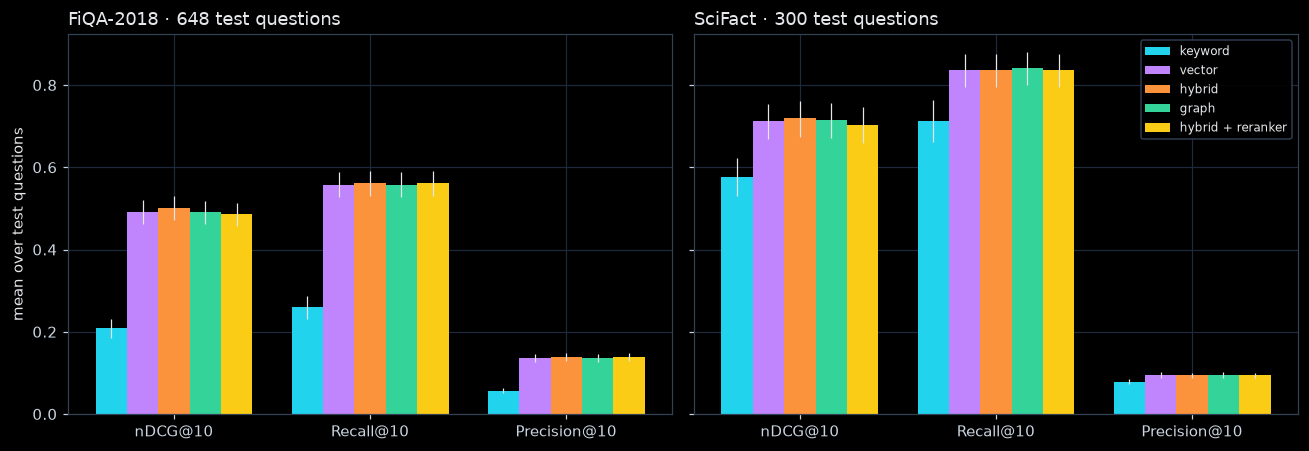

In [21]:
import matplotlib.pyplot as plt

PALETTE = ["#22d3ee", "#c084fc", "#fb923c", "#34d399", "#facc15", "#60a5fa", "#f472b6", "#a3e635"]
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "savefig.facecolor": "black",
    "axes.edgecolor": "#334155", "axes.labelcolor": "#e5e7eb", "text.color": "#e5e7eb",
    "xtick.color": "#cbd5e1", "ytick.color": "#cbd5e1", "grid.color": "#1e293b", "axes.grid": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "font.size": 10, "axes.titlesize": 12, "axes.titlelocation": "left",
    "legend.frameon": True, "legend.facecolor": "black", "legend.edgecolor": "#334155", "legend.framealpha": 0.9,
    "axes.axisbelow": True, "figure.dpi": 110})
CHART_METRICS, width = ["nDCG@10", "Recall@10", "Precision@10"], 0.16
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, ds in zip(axes, DATASETS):
    for i, strategy in enumerate(STRATEGIES):
        frame = PER_QUERY[(ds, strategy)]
        means = [frame[m].mean() for m in CHART_METRICS]
        cis = np.array([bootstrap_ci(frame[m]) for m in CHART_METRICS])
        ax.bar(np.arange(3) + (i - 2) * width, means, width, label=strategy,
               yerr=[np.subtract(means, cis[:, 0]), cis[:, 1] - means], error_kw={"ecolor": "#e5e7eb", "lw": 0.8})
    ax.set_xticks(np.arange(3), CHART_METRICS)
    ax.set_title(f"{DATASETS[ds]['name']} · {len(TEST[ds])} test questions")
axes[0].set_ylabel("mean over test questions")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

**How to read the result.** Read each panel left to right: the first group is ranking quality, the second coverage of the relevant documents, the third how much of the top 10 is relevant.

In this run the keyword bar is the shortest in every group on both datasets, and the other four bars in a group are level within their intervals. Recall@10 shows the gap in coverage: on SciFact the four reach 0.836 to 0.841 against keyword search's 0.713. Precision@10 is low for every strategy because a question has few relevant documents: 2.63 on FiQA and 1.13 on SciFact on average, so even a perfect top 10 scores about 0.26 and 0.11.

## 3.3 ⭐ · The hybrid weight decides whether fusion helps

**Why this step.** Hybrid search is often run with equal weights. The weight α decides whether fusion beats its best input.

**How:** the hybrid statement of 2.3 runs on every test question at seven values of α. α = 0 is the keyword list alone, α = 1 the vector list alone, α = 0.5 equal weight. The dashed line is vector search from 3.1.

The α = 0.8 used in this notebook was picked on FiQA's dev queries in the full study, never on these test questions. To tune α for your own data, hold out a set of questions, pick α on them, and report on the rest: an α picked on the questions you report overstates the result.

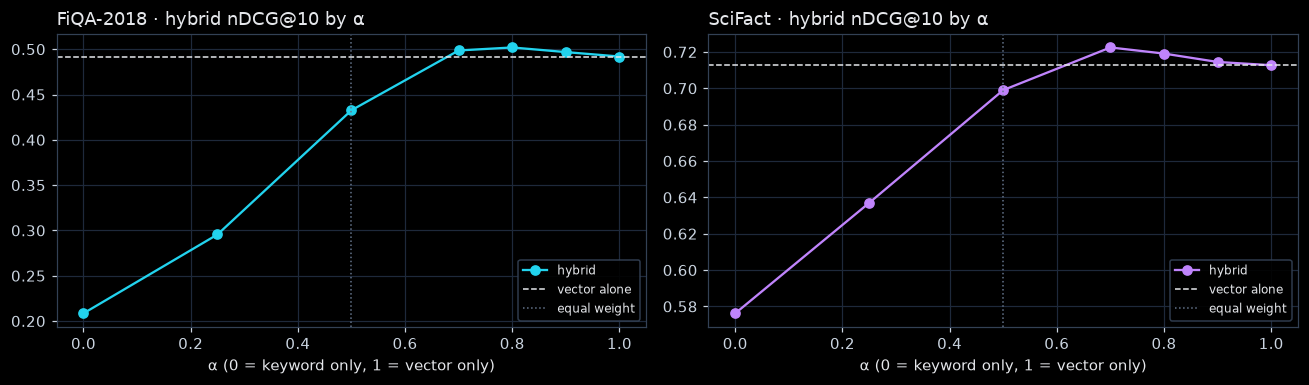

α,0.00,0.25,0.50,0.70,0.80,0.90,1.00
FiQA-2018,0.208,0.296,0.433,0.499,0.502,0.497,0.492
SciFact,0.576,0.637,0.699,0.722,0.719,0.714,0.713


In [22]:
ALPHAS = [0, 0.25, 0.5, 0.7, 0.8, 0.9, 1]
SWEEP = pd.DataFrame({DATASETS[ds]["name"]: [np.mean([score([d for d, _ in search(ds, q, "hybrid", alpha=a)[0]],
                                                            QRELS[ds][q])["nDCG@10"] for q in TEST[ds]])
                                             for a in ALPHAS] for ds in DATASETS}, index=pd.Index(ALPHAS, name="α"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, (ds, spec), color in zip(axes, DATASETS.items(), PALETTE):
    ax.plot(ALPHAS, SWEEP[spec["name"]], marker="o", color=color, label="hybrid")
    ax.axhline(PER_QUERY[(ds, "vector")]["nDCG@10"].mean(), ls="--", color="#e5e7eb", lw=1, label="vector alone")
    ax.axvline(0.5, ls=":", color="#64748b", lw=1, label="equal weight")
    ax.set_title(f"{spec['name']} · hybrid nDCG@10 by α")
    ax.set_xlabel("α (0 = keyword only, 1 = vector only)")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
SWEEP.round(3).T

**How to read the result.** Each line runs from keyword alone (α = 0) to vector alone (α = 1); the dotted line marks equal weight and the dashed line vector search. Fusion helps only where the solid line is above the dashed one. The table below the chart holds the points.

In this run equal weight loses to vector search alone on both datasets: α = 0.5 scores 0.433 on FiQA against vector search's 0.492, and 0.699 on SciFact against 0.713. Each line peaks at a high α, 0.8 on FiQA (0.502) and 0.7 on SciFact (0.722), and from 0.7 to 0.9 hybrid is at or above vector search on both. The best gain over vector search is small, 0.010 on FiQA and 0.009 on SciFact, because keyword search is much the weaker list: the more weight it gets, the more of its misses push good vector results down.

## 3.4 · Oracle Text against BEIR's published BM25

**Why this step.** BEIR's keyword baseline is BM25, the usual reference point for a keyword score.

**How:** the keyword nDCG@10 from 3.1 next to BM25 as reported in the BEIR paper (Thakur et al., 2021), which ran on the full corpora.

In [23]:
pd.DataFrame({"Oracle Text, this run": [PER_QUERY[(ds, "keyword")]["nDCG@10"].mean() for ds in DATASETS],
              "BM25, BEIR paper": [spec["bm25"] for spec in DATASETS.values()],
              "corpus here": ["20,000-document sample", "full"]},
             index=[spec["name"] for spec in DATASETS.values()]).round(3)

,"Oracle Text, this run","BM25, BEIR paper",corpus here
FiQA-2018,0.208,0.236,"20,000-document sample"
SciFact,0.576,0.665,full


**How to read the result.** One row per dataset: the keyword nDCG@10 measured here, BM25's published score, and the corpus searched here.

In this run Oracle Text scores below BM25 on both datasets: 0.208 against 0.236 on FiQA, although the FiQA corpus here is a 20,000-document sample, which raises scores, and 0.576 against 0.665 on SciFact's full corpus. The scoring formulas differ. Oracle Text's default score grows with how often a word occurs in a document and how rare the word is in the corpus (about `3f(1 + log(N/n))` for `f` occurrences, `N` documents and `n` documents containing the word), with no document-length normalisation. BM25 normalises by document length and saturates term frequency, so a long document that repeats a word gains less. The example in 2.6 shows the effect: the top five keyword results were posts of 486 to 1,100 words.

> ### 📌 Key Takeaways — Part 3
>
> - The strategies built on vectors lead on both datasets, and **keyword search alone trails far behind**, most on FiQA, where answers use other words than the questions.
> - **Weighted hybrid** (α 0.7–0.8) has the best mean on both, by at most 0.010 over vector search, inside the intervals; **equal weight loses** to vector search alone.
> - The graph matched vector search, and the web-search **reranker lowered** nDCG@10 while costing the most time.
> - Report **intervals**, and pick settings on held-out questions, never on the ones you report.

# Part 4 · Which strategy to use

## 4.1 ⭐ · The decision table

**Why this step.** Part 3 measured; this table turns the measurements into choices.

**How:** each row is a situation you can recognise in your own data, the strategy to try first, and the evidence from this run.

| Your situation | Use | Why, with this run's evidence |
|---|---|---|
| A first system, or answers worded differently from the questions | **Vector search** | Within 0.010 nDCG@10 of the best strategy on both datasets (FiQA 0.492, SciFact 0.713) with one statement; keyword search alone reached 0.208 on FiQA |
| You can afford a second search per question | **Hybrid, weighted toward vector (α 0.7–0.8)** | The highest mean on both datasets (FiQA 0.502, SciFact 0.719), by a margin inside the 95% intervals, for 5.9 ms more than vector search at the median on FiQA (23.1 against 17.2) |
| You fuse two ranked lists | **Weight them, and tune the weight on held-out questions** | Equal weight lost to vector search alone on both datasets: 0.433 against 0.492 on FiQA, 0.699 against 0.713 on SciFact |
| Questions reuse the answers' exact terms, names or codes | **Keep keyword search, inside the hybrid** | Keyword search reached 81% of vector search's nDCG@10 on SciFact, against 42% on FiQA, and lost on both when used alone |
| Relevant documents link to each other through real relationships: threads, citations, product families | **Graph search, after a test on your data** | A graph built from the same embeddings matched vector search (FiQA 0.491 against 0.492, SciFact 0.714 against 0.713): its edges carried nothing the vectors lacked |
| You consider a reranker | **Only one that wins on your held-out questions** | This web-search cross-encoder lowered nDCG@10 on both datasets (FiQA 0.502 → 0.485, SciFact 0.719 → 0.703) and was the slowest strategy, 180.3 ms per question at the median on FiQA |

## 4.2 · The decision in one picture

<img src="img/strategy_choice.png" alt="Decision diagram: judge your own questions, start with vector search, add weighted hybrid if questions reuse the answers' words, add a graph or a reranker only if it wins on held-out questions" width="541">

<details>
<summary>Mermaid source</summary>

```mermaid
flowchart TB
    classDef user fill:#1a0714,stroke:#f472b6,stroke-width:2px,color:#fce7f3
    classDef app fill:#061a22,stroke:#22d3ee,stroke-width:2px,color:#cffafe
    classDef llm fill:#160a2b,stroke:#c084fc,stroke-width:2px,color:#f3e8ff
    classDef dm fill:#2a1204,stroke:#fb923c,stroke-width:3px,color:#ffedd5
    classDef db fill:#03210f,stroke:#34d399,stroke-width:2px,color:#d1fae5
    classDef mem fill:#221d03,stroke:#facc15,stroke-width:2px,color:#fef9c3
    classDef tool fill:#07162e,stroke:#60a5fa,stroke-width:2px,color:#dbeafe
    classDef code fill:#0f1a05,stroke:#a3e635,stroke-width:2px,color:#ecfccb
    classDef gate fill:#241400,stroke:#fbbf24,stroke-width:2px,color:#fef3c7
    classDef risk fill:#2a0710,stroke:#fb7185,stroke-width:2px,color:#ffe4e6
    linkStyle default stroke:#7dd3fc,stroke-width:1.6px
    A["YOUR QUESTIONS<br/>judge 50–100 real ones · hold half out"]:::user
    B["VECTOR SEARCH<br/>the baseline to beat"]:::db
    C{"Do questions reuse the<br/>answers' exact words?"}:::gate
    D["HYBRID · WEIGHTED<br/>α 0.7–0.8 toward vector"]:::db
    E["KEEP VECTOR SEARCH"]:::db
    F{"Does a graph or a reranker<br/>win on the held-out half?"}:::gate
    G["ADD IT<br/>and budget its latency"]:::dm
    H["SHIP WITHOUT IT<br/>as in this run"]:::code
    A --> B --> C
    C -->|"often: terms, names, codes"| D
    C -->|"rarely: paraphrase"| E
    D --> F
    E --> F
    F -->|"yes"| G
    F -->|"no"| H
```

</details>

> ### 📌 Key Takeaways — Part 4
>
> - Start with **vector search**: it was within 0.010 nDCG@10 of the best strategy on both datasets.
> - Add keyword search through a **weighted hybrid**, weighted toward vector; equal weight lost to vector search alone.
> - Treat a **graph** and a **reranker** as experiments: here the graph matched vector search and the reranker lowered the hybrid's ranking.
> - Decide on **your own judged questions**: tune on one set, report on another, with intervals.

## Where to go deeper

- **The appbook**, `retrieval_evaluation/appbook` on http://localhost:8725: the full study's leaderboard on three datasets, every test question's rankings side by side, sliders for the hybrid and graph settings, and the full decision guide.
- **The full study**, `retrieval_evaluation/notes/backup/beir_retrieval_benchmark.full_study.ipynb`: a third dataset (ArguAna), every setting tuned on dev queries, significance tests, a second embedding model, approximate (HNSW) vector search, and how corpus size moves the scores.

The `BEIR7_` tables stay in Oracle for the next run and for the appbook.